🚀 TEST DU MODULE E5 - RÉCONCILIATION

📊 Création des données de test...
   ✅ Source (MILES) : 50 enregistrements
   ✅ Cible (SAP) : 50 enregistrements

🔧 Initialisation du moteur...

🔍 RÉCONCILIATION : CONTRACT
   Clé de jointure : contract_id

   📊 Analyse des clés :
      - Clés communes : 48
      - Manquants source : 2
      - Manquants cible : 2
      - Taux de correspondance : 92.3%

   🔍 Comparaison des 48 enregistrements communs...
      - Colonnes comparées : 5

   📊 RÉSUMÉ :
      - Source : 50 enregistrements
      - Cible : 50 enregistrements
      - Clés communes : 48
      - Taux de correspondance : 92.3%
      - Écarts trouvés : 5
        * Critiques : 2 🔴
        * Mineurs : 3 🟡
      - Taux d'écart : 2.08%

   💡 RECOMMANDATIONS :
      [HAUTE] 2 écarts critiques détectés. Investigation immédiate requise.
      [MOYENNE] La colonne 'amount' concentre 2 écarts. Vérifier la logique de transformation.
      [MOYENNE] 2 enregistrements manquants dans la source. Vérifier l'e

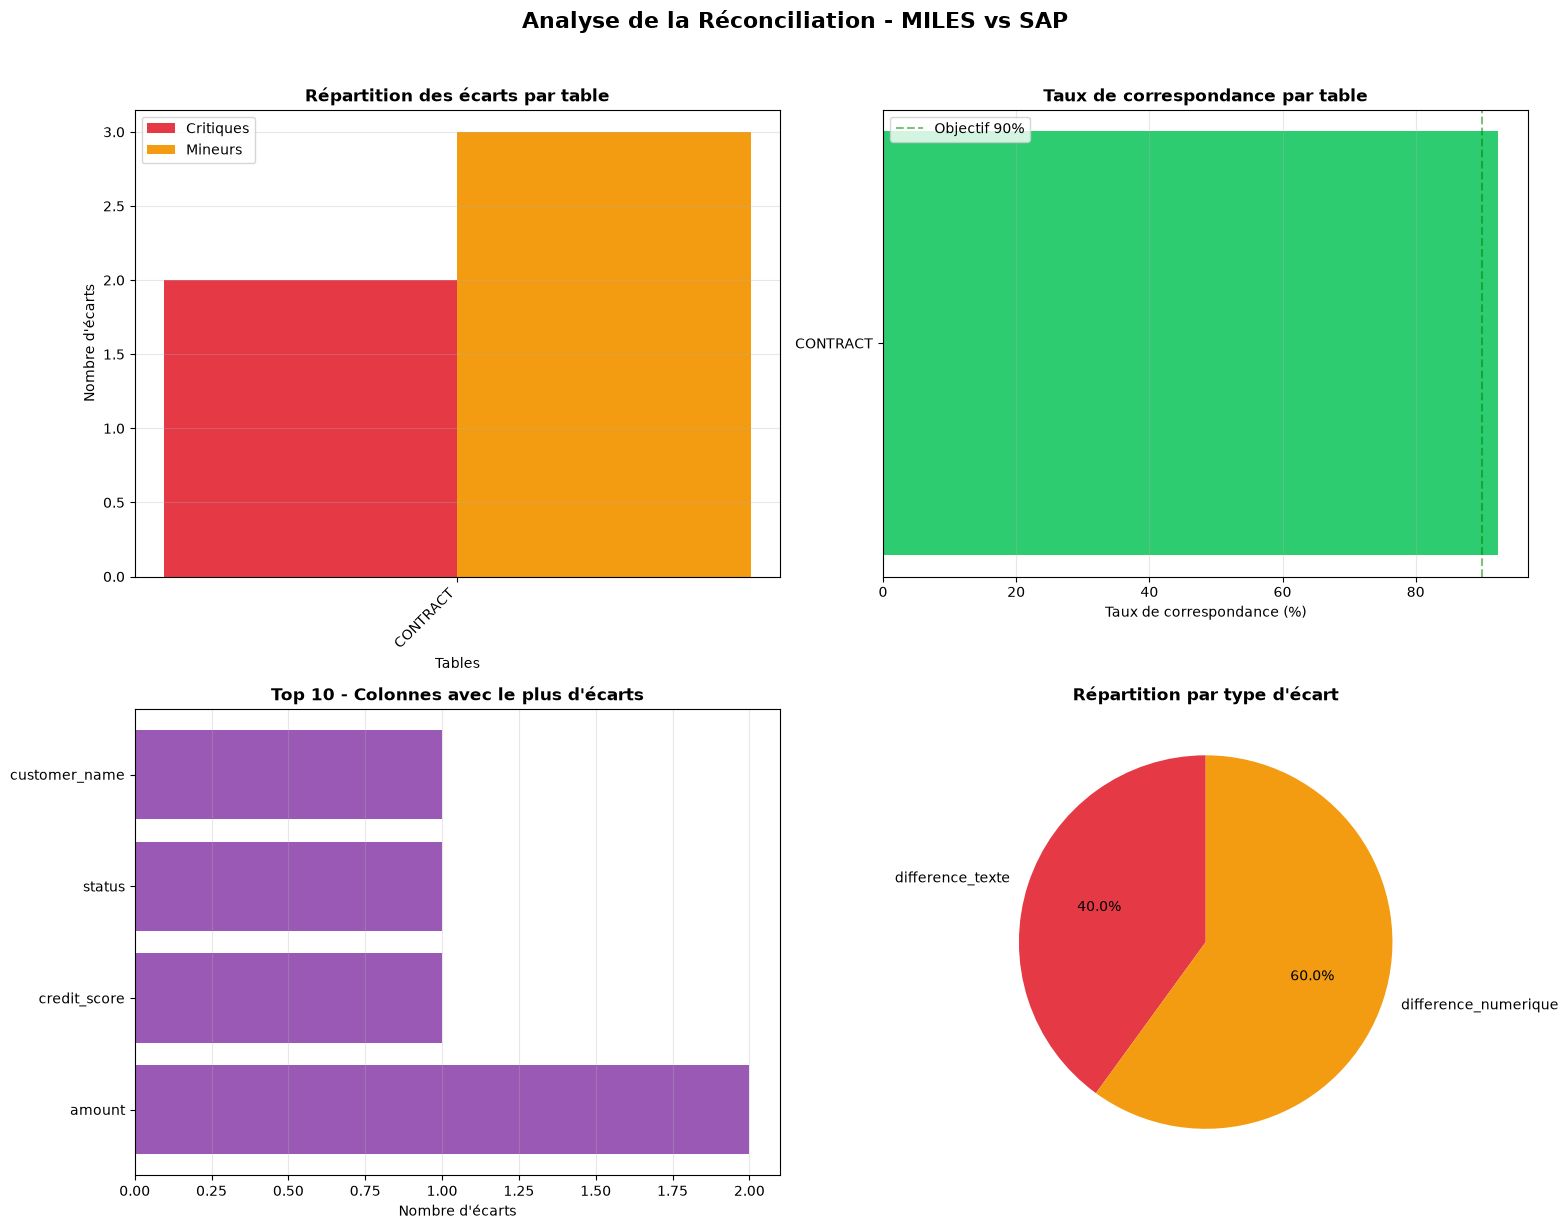

   💾 Rapport JSON exporté : ..\docs\rapport_reconciliation.json
   💾 Rapport Excel exporté : ..\docs\rapport_reconciliation.xlsx

🏁 FIN - Module E5 testé avec succès !


In [1]:
# Cellule : Test du module E5 - Réconciliation

import sys
sys.path.append('.')  # Pour que Jupyter trouve le fichier reconciliation.py

import importlib
import reconciliation
importlib.reload(reconciliation)

from reconciliation import ReconciliationEngine
import pandas as pd
import numpy as np

print("=" * 60)
print("🚀 TEST DU MODULE E5 - RÉCONCILIATION")
print("=" * 60)

# ============================================================
# 1. Créer des données de test (source MILES vs cible SAP)
# ============================================================

print("\n📊 Création des données de test...")

np.random.seed(42)
n = 50

# SOURCE (MILES)
source_data = {
    "contract_id": list(range(1, n+1)),
    "reference": [f"REF{i:03d}" for i in range(1, n+1)],
    "amount": np.random.normal(20000, 5000, n).round(2),
    "status": np.random.choice(["ACTIF", "CLOTURE", "RESILIE"], n),
    "customer_name": [f"Client {chr(65+i%26)}" for i in range(n)],
    "credit_score": np.random.normal(700, 80, n).round(0)
}
df_source = pd.DataFrame(source_data)

# CIBLE (SAP) avec écarts volontaires
df_cible = df_source.copy()

# Ajouter des écarts ciblés
df_cible.loc[5, 'amount'] = 21000.50        # Écart de montant (critique)
df_cible.loc[10, 'status'] = "ACTIF"         # Statut changé
df_cible.loc[15, 'customer_name'] = "Client Modifié"  # Nom modifié
df_cible.loc[20, 'credit_score'] = 650       # Score modifié
df_cible.loc[25, 'amount'] = 30000.00        # Écart important

# Supprimer 2 enregistrements (manquants dans la cible)
df_cible = df_cible.drop([30, 31]).reset_index(drop=True)

# Ajouter 2 enregistrements en trop (manquants dans la source)
df_cible = pd.concat([df_cible, pd.DataFrame({
    "contract_id": [51, 52],
    "reference": ["REF051", "REF052"],
    "amount": [25000, 30000],
    "status": ["ACTIF", "ACTIF"],
    "customer_name": ["Client Z", "Client Y"],
    "credit_score": [700, 720]
})], ignore_index=True)

print(f"   ✅ Source (MILES) : {len(df_source)} enregistrements")
print(f"   ✅ Cible (SAP) : {len(df_cible)} enregistrements")

# ============================================================
# 2. Initialiser le moteur de réconciliation
# ============================================================

print("\n🔧 Initialisation du moteur...")
engine = ReconciliationEngine()

# ============================================================
# 3. Exécuter la réconciliation
# ============================================================

tolerances = {"amount": 0.01, "credit_score": 5}
colonnes_critiques = ["REFERENCE", "CONTRACT_ID", "AMOUNT"]

resultat = engine.comparer(
    table_name="CONTRACT",
    source_data=df_source,
    cible_data=df_cible,
    cle="contract_id",
    tolerances=tolerances,
    colonnes_critiques=colonnes_critiques
)

# ============================================================
# 4. Afficher le rapport
# ============================================================

engine.afficher_rapport()

# ============================================================
# 5. Générer les visualisations
# ============================================================

engine.visualiser_ecarts()

# ============================================================
# 6. Exporter les rapports
# ============================================================

engine.exporter_rapport_json()
engine.exporter_rapport_excel()

print("\n" + "=" * 60)
print("🏁 FIN - Module E5 testé avec succès !")
print("=" * 60)